In [1]:
import numpy as np

ratings = np.loadtxt("ml-32m/ratings.csv", delimiter = ",", skiprows= 1)

# ratings = ratings[:1000000]

In [2]:
cols = ['userId', 'movieId', 'rating', 'timestamp']

col_to_ind = {col:ind for ind,col in enumerate(cols)}

In [3]:
users_to_index = {}
index_to_users = []

movies_to_index = {}
index_to_movies = []

data_by_users = []
data_by_movies = []

In [4]:
len(ratings[:,col_to_ind["userId"]])

32000204

In [5]:
index_to_users = np.unique(ratings[:,col_to_ind["userId"]]).tolist()
users_to_index = {user:index for index,user in enumerate(index_to_users)}


index_to_movies = np.unique(ratings[:,col_to_ind["movieId"]]).tolist()
movies_to_index = {movie:index for index,movie in enumerate(index_to_movies)}

In [6]:
def process_user_ratings(ratings_arr,index_to_users):
  data_by_users =  [[] for _ in range(len(index_to_users))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_users[users_to_index[user]].append((movies_to_index[movie],rating))

  return data_by_users


In [7]:
def process_movie_ratings(ratings_arr,index_to_movies):
  data_by_movies =  [[] for _ in range(len(index_to_movies))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_movies[movies_to_index[movie]].append((users_to_index[user],rating))

  return data_by_movies


In [8]:
# splitting into train and test

import random
random.seed(42)

CUTOFF = 0.7

random_nums = [random.uniform(0,1) > CUTOFF for i in range(ratings.shape[0])]

test_locs = [i for i,j in enumerate(random_nums) if j]
train_locs = [i for i,j in enumerate(random_nums) if not j]

print(len(test_locs))
print(len(train_locs))

ratings_test = ratings[test_locs]
ratings_train = ratings[train_locs]

9595382
22404822


In [9]:
data_by_users_train = process_user_ratings(ratings_train, index_to_users)

data_by_users_test = process_user_ratings(ratings_test, index_to_users )


In [10]:
data_by_movies_test = process_movie_ratings(ratings_test, index_to_movies)
data_by_movies_train =  process_movie_ratings(ratings_train, index_to_movies)

In [11]:
import numpy as np

N_ITER = 20
lamb = 0.09
gamma = 0.1
tau = 0.9
VERBOSITY = 1
K = 8

user_biases = np.zeros(len(data_by_users_train))
movies_biases = np.zeros(len(data_by_movies_train))

U = np.random.normal(size = (len(data_by_users_train),K))
V = np.random.normal(size = (len(data_by_movies_train),K))

U

array([[-0.39859673,  1.39971814, -2.08503878, ..., -0.91471629,
        -0.57663491, -0.52216913],
       [ 0.62362176,  0.49381151,  1.30799215, ...,  0.07911305,
         1.27831444, -0.38982832],
       [-1.29228696, -0.02792951,  1.86069444, ...,  1.03481819,
         0.24569763, -0.8135486 ],
       ...,
       [-0.70178395,  0.16457907, -1.8908641 , ..., -0.165495  ,
        -1.43056751, -1.00930149],
       [ 0.32082232, -0.37267925,  0.9991582 , ...,  0.3720312 ,
         0.98915374, -1.1827958 ],
       [-1.09211488, -1.8470073 ,  1.08013401, ...,  1.97893552,
        -0.73257796,  1.25515283]], shape=(200948, 8))

In [12]:
train_rmses = []
test_rmses = []
test_losses = []
train_losses = []

for _ in range(N_ITER):

  # update bias
  for i, item_ratings in enumerate(data_by_users_train):
    bias = 0
    item_counter = 0
    for (n,r) in item_ratings:
      bias += lamb * (r - movies_biases[n])
      item_counter += 1
    bias = bias / (lamb * item_counter + gamma)
    user_biases[i] = bias

  for m, item_ratings in enumerate(data_by_users_train):
    item_counter = 0
    u_comp1 = np.zeros([K,K])
    u_comp2 = np.zeros(K)
    for (n,r) in item_ratings:
      u_comp1 += lamb * np.outer(V[n],V[n])
      u_comp2 += lamb * (V[n] * (r - user_biases[m] - movies_biases[n]))
      item_counter += 1
    u_comp1 = u_comp1 + tau * np.identity(K)
    U[m] = np.linalg.solve(u_comp1,u_comp2)

  for i, item_ratings in enumerate(data_by_movies_train):
    bias = 0
    item_counter = 0
    for (n,r) in item_ratings:
      bias += lamb * (r - user_biases[n])
      item_counter += 1
    bias = bias / (lamb * item_counter + gamma)
    movies_biases[i] = bias

  for n, item_ratings in enumerate(data_by_movies_train):
    item_counter = 0
    v_comp1 = np.zeros([K,K])
    v_comp2 = np.zeros(K)
    for (m,r) in item_ratings:
      v_comp1 += lamb * np.outer(U[m],U[m])
      v_comp2 += lamb * (U[m] * (r - user_biases[m] - movies_biases[n]))
      item_counter += 1
    v_comp1 = v_comp1 + tau * np.identity(K)
    V[n] = np.linalg.solve(v_comp1,v_comp2)

  error = 0
  loss = 0
  items_count = 0
  for m,ratings in enumerate(data_by_users_train):
    for (n,r) in ratings:
      pred = (U[m] @ V[n]) + user_biases[m] + movies_biases[n]
      true = r
      error_ = (pred - true)**2
      error += error_
      loss += error_
      items_count += 1
  u_loss_comp = 0
  v_loss_comp = 0
  for u in U:
    u_loss_comp += u @ u
  for v in V:
    v_loss_comp += v @ v
  train_RMSE = (error/items_count) ** (1/2)
  train_rmses.append(train_RMSE)
  loss += (u_loss_comp + v_loss_comp) * tau + (sum(user_biases**2) + sum(movies_biases**2)) * gamma
  train_loss = loss/items_count
  train_losses.append(train_loss)


  error = 0
  loss = 0
  items_count = 0
  for m,ratings in enumerate(data_by_users_test):
    for (n,r) in ratings:
      pred = (U[m] @ V[n]) + user_biases[m] + movies_biases[n]
      true = r
      error_ = (pred - true)**2
      error += error_
      loss += error_
      items_count += 1
  u_loss_comp = 0
  v_loss_comp = 0
  for u in U:
    u_loss_comp += u @ u
  for v in V:
    v_loss_comp += v @ v
  test_RMSE = (error/items_count) ** (1/2)
  test_rmses.append(test_RMSE)
  loss += (u_loss_comp + v_loss_comp) * tau + (sum(user_biases**2) + sum(movies_biases**2)) * gamma
  test_loss = loss/items_count
  test_losses.append(test_loss)

  if _ % VERBOSITY == 0:
    print(f"Round {_}:  Train RMSE: {train_RMSE} Test RMSE: {test_RMSE}")
    print(f"Round {_}:  Train loss: {train_loss} Test loss: {test_loss}")
print(f"After training:  Train RMSE: {train_RMSE} Test RMSE: {test_RMSE}")
print(f"After training:  Train loss: {train_loss} Test loss: {test_loss}")

Round 0:  Train RMSE: 0.8328621840134179 Test RMSE: 0.8866278743987447
Round 0:  Train loss: 0.7069893088417596 Test loss: 0.8172337351129048
Round 1:  Train RMSE: 0.7926463415742426 Test RMSE: 0.8566354474635159
Round 1:  Train loss: 0.6414409192922841 Test loss: 0.7645352947367542
Round 2:  Train RMSE: 0.7681367083394987 Test RMSE: 0.8308645868547202
Round 2:  Train loss: 0.6032082954216864 Test loss: 0.7210973929106324
Round 3:  Train RMSE: 0.7555023341812072 Test RMSE: 0.8173834254664644
Round 3:  Train loss: 0.5839132121307019 Test loss: 0.6987723549261394
Round 4:  Train RMSE: 0.7487915135633795 Test RMSE: 0.8097906886460766
Round 4:  Train loss: 0.5737157827696022 Test loss: 0.6861785895768678
Round 5:  Train RMSE: 0.7449102560420863 Test RMSE: 0.8051127767252444
Round 5:  Train loss: 0.5677896745787101 Test loss: 0.6783237813427658
Round 6:  Train RMSE: 0.7424403226630562 Test RMSE: 0.8020471882196786
Round 6:  Train loss: 0.5639735625764494 Test loss: 0.6730642632891078
Round 

In [6]:
N_ITER = 20

train_rmses = [
    0.8328621840134179, 0.7926463415742426, 0.7681367083394987,
    0.7555023341812072, 0.7487915135633795, 0.7449102560420863,
    0.7424403226630562, 0.740742419739345, 0.7395068853822541,
    0.7385738944136823, 0.7378496832174313, 0.7372723756108668,
    0.7367992269145754, 0.7364007488933174, 0.7360569864612059,
    0.7357549148708338, 0.7354866428523917, 0.7352479939855829,
    0.7350370030497366, 0.7348525235699079
]

test_rmses = [
    0.8866278743987447, 0.8566354474635159, 0.8308645868547202,
    0.8173834254664644, 0.8097906886460766, 0.8051127767252444,
    0.8020471882196786, 0.7999259721168908, 0.7983870952295031,
    0.797232585329154, 0.7963427113678418, 0.7956380768967068,
    0.7950639121147489, 0.7945824145776893, 0.7941681897979944,
    0.7938050408039657, 0.7934834381636507, 0.7931983978595109,
    0.7929476022882609, 0.7927298492244438
]

train_losses = [
    0.7069893088417596, 0.6414409192922841, 0.6032082954216864,
    0.5839132121307019, 0.5737157827696022, 0.5677896745787101,
    0.5639735625764494, 0.5613042902308952, 0.559319657457638,
    0.5577828758523636, 0.5565556521223832, 0.5555469350682698,
    0.5546939165562006, 0.5539533119255509, 0.5532958440632864,
    0.552702391922104, 0.5521613317912074, 0.551666448305619,
    0.5512147506207108, 0.5508044643270903
]

test_losses = [
    0.8172337351129048, 0.7645352947367542, 0.7210973929106324,
    0.6987723549261394, 0.6861785895768678, 0.6783237813427658,
    0.6730642632891078, 0.6693136185475651, 0.6664903792639685,
    0.6642798910933522, 0.6624929302280763, 0.6610043019306691,
    0.6597277426057253, 0.6586037596125882, 0.6575923986607698,
    0.6566681467890239, 0.6558159092627288, 0.655027653649477,
    0.6542995032322094, 0.6536293733429878
]

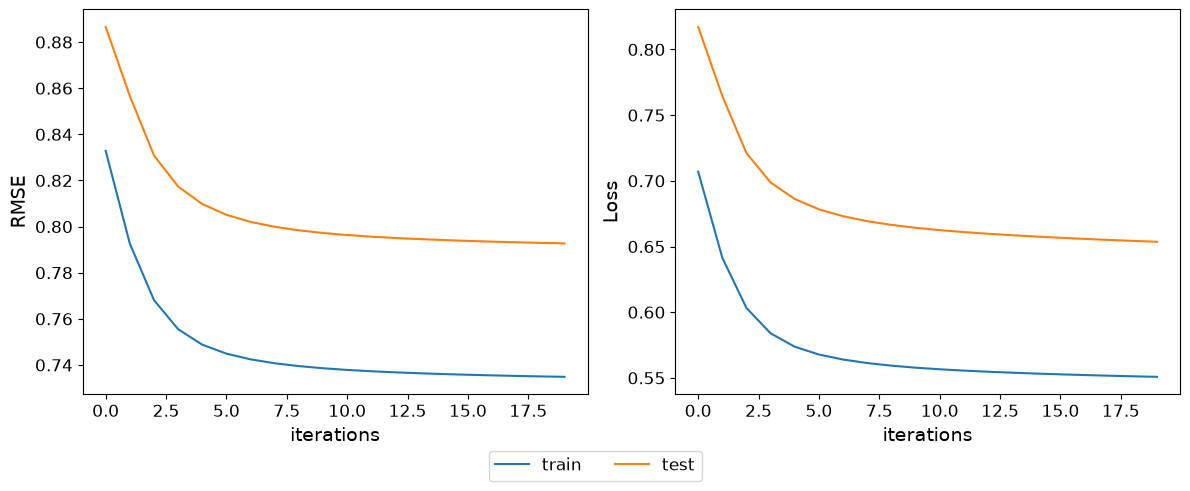

In [8]:
from matplotlib import pyplot as plt

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

fig,axs = plt.subplots(1,2, figsize = (12,5))

axs[0].plot(range(N_ITER), train_rmses, label = "train")
axs[0].plot(range(N_ITER), test_rmses, label = "test")
axs[0].set_ylabel("RMSE")
axs[0].set_xlabel("iterations")

axs[1].plot(range(N_ITER), train_losses, label = "train")
axs[1].plot(range(N_ITER), test_losses, label = "test")
axs[1].set_ylabel("Loss")
axs[1].set_xlabel("iterations")


handles, labels = axs[1].get_legend_handles_labels()

fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.01), fontsize = 12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.2)

plt.savefig("images/vectors_biases_loss_progression_plot.svg")

plt.show()

In [21]:
np.savez("embeddings.npz", U = U, V = V, user_biases = user_biases, movies_biases = movies_biases, index_to_users = index_to_users, index_to_movies = index_to_movies)